In [29]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Load the 'taxis' dataset
df=sns.load_dataset("taxis")
print(df)

                  pickup             dropoff  passengers  distance  fare  \
0    2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0   
1    2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0   
2    2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5   
3    2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0   
4    2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0   
...                  ...                 ...         ...       ...   ...   
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total   color      payment            pickup_zone  \
0     2.15    0

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [ ]:
df.columns

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [ ]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
df = df.dropna(subset=['pickup', 'fare'])

In [ ]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


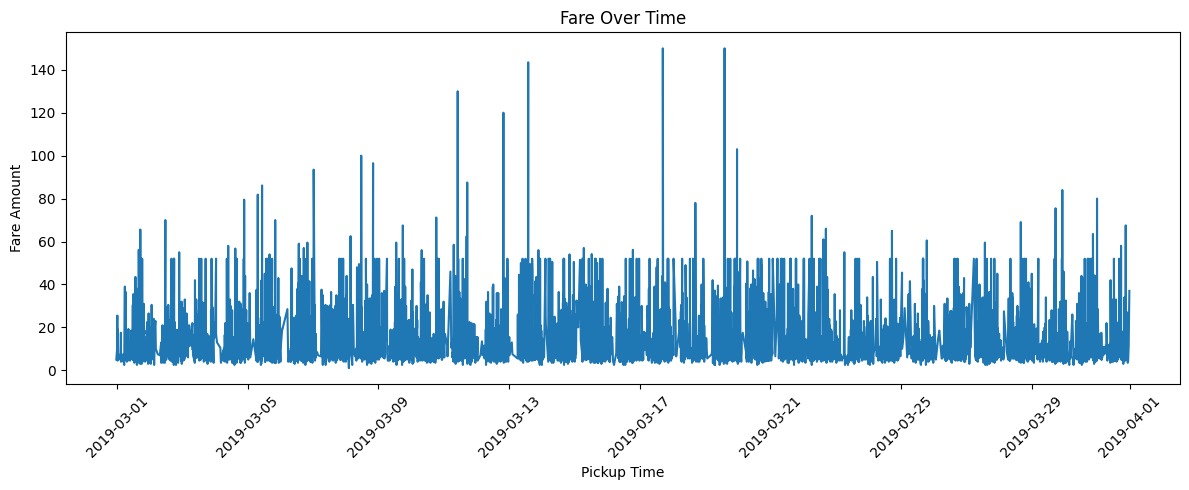

In [ ]:
#★ Line Chart
#Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime  format before plotting
# Convert pickup column into datetime

df['pickup'] = pd.to_datetime(df['pickup'])

# Sort data by pickup time
df = df.sort_values('pickup')

# Create line chart
plt.figure(figsize=(12,5))

plt.plot(df['pickup'], df['fare'])

plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare Amount')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()






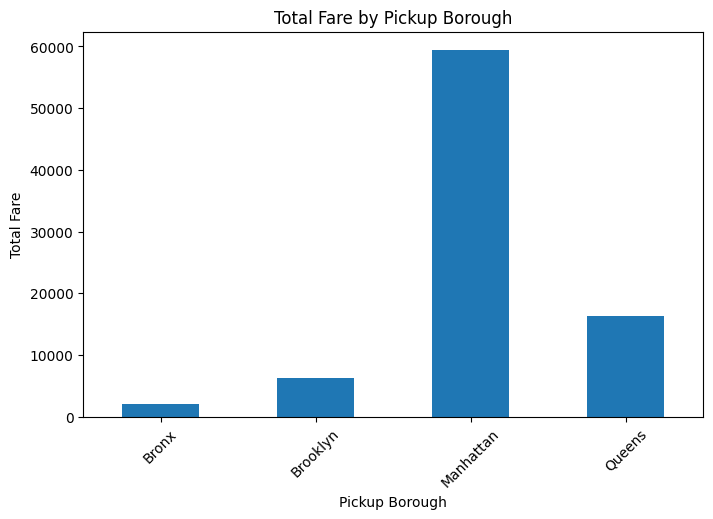

In [ ]:
#★ Bar Chart
#Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.

borough_fare = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(8,5))

borough_fare.plot(kind='bar')

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.xticks(rotation=45)
plt.show()

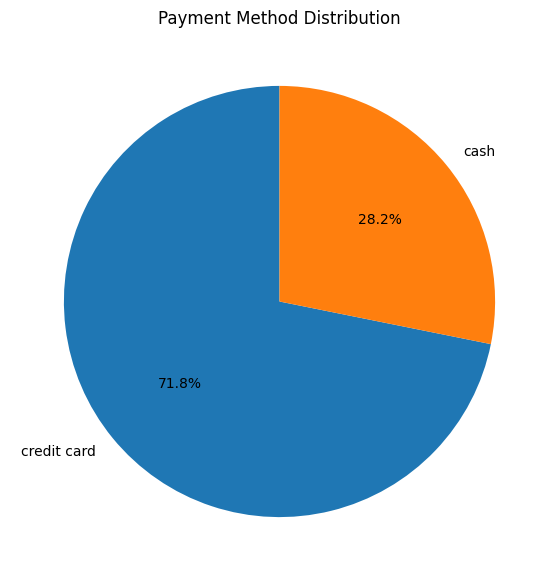

In [ ]:
#★ Pie Chart
#Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.). Each slice should represent the count of trips for a specific payment method.

payment_count = df['payment'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    payment_count,
    labels=payment_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Payment Method Distribution')
plt.show()





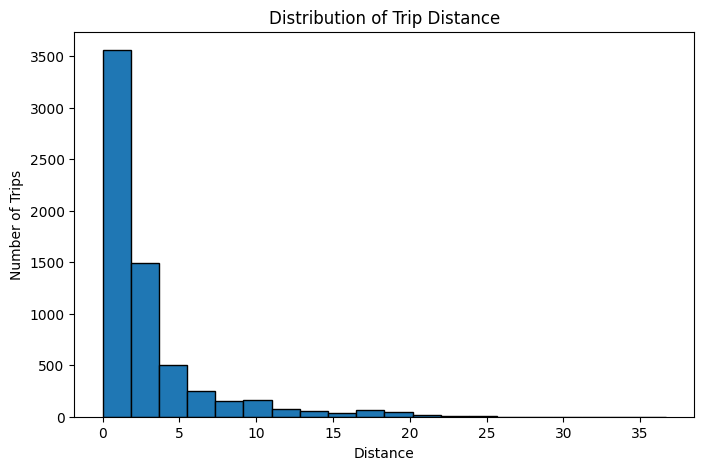

In [ ]:
#★ Histogram
#Create a histogram to visualize the distribution of distance. Customize the number of bins for better granularity and ensure the plot is easy to interpret.

plt.figure(figsize=(8,5))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')

plt.show()



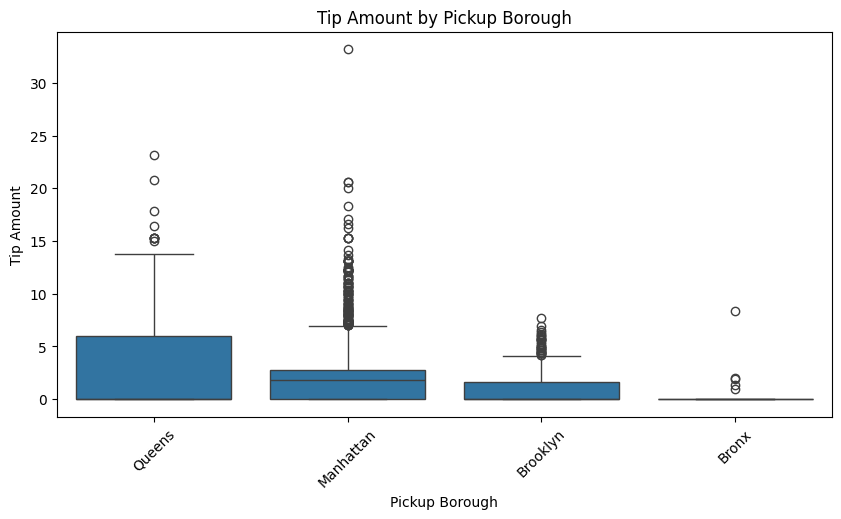

In [21]:
#★ Box Plot

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip'
)

plt.title('Tip Amount by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)
plt.show()

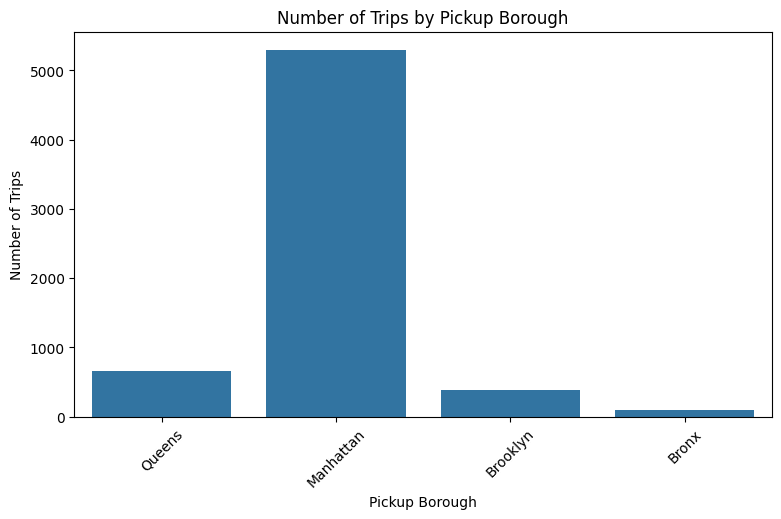

In [22]:
#Visualizations using Seaborn:
#★ Count Plot
#Count Plot – Number of Trips by Borough
plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    x='pickup_borough'
)

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')

plt.xticks(rotation=45)
plt.show()


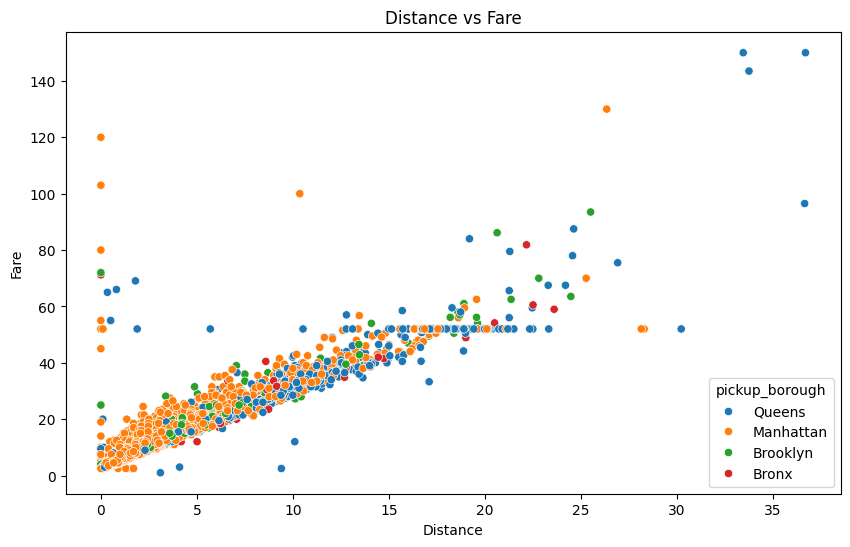

In [23]:
#★ Scatter Plot
#Scatter Plot – Distance vs Fare

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Distance vs Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.show()



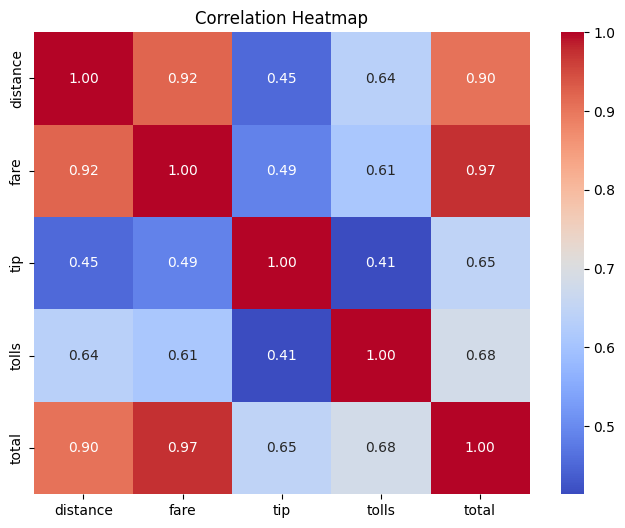

In [24]:
#Heatmap – Correlation Between Numerical Variables

corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()


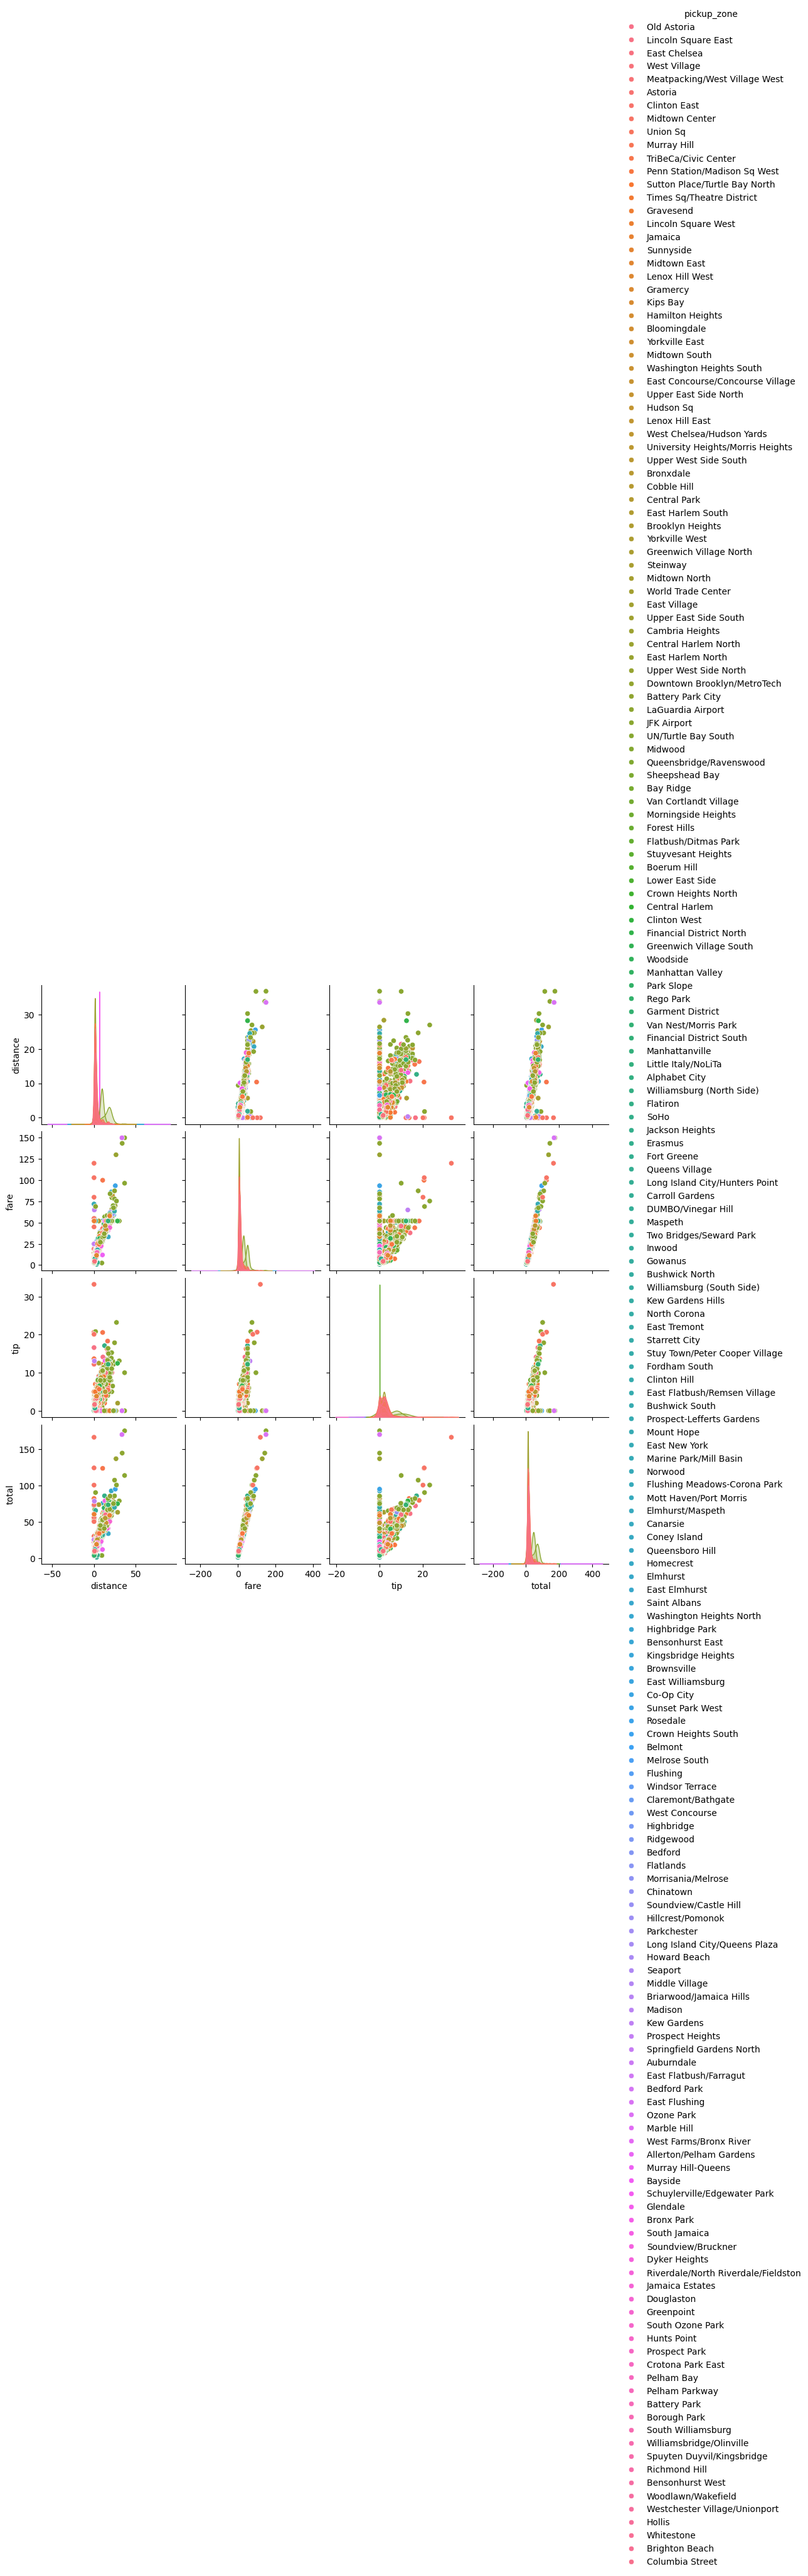

In [28]:
#Pair Plot – Pairwise Relationships

sns.pairplot(
    data=df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()


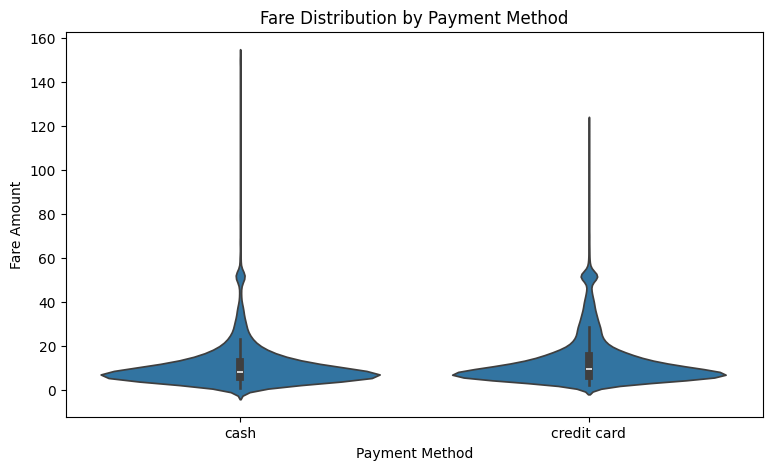

In [27]:
#Violin Plot – Fare Distribution by Payment Method

plt.figure(figsize=(9,5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount')

plt.show()
